# 03 — Statistical Analysis and Predictive Modelling
**Parts B through I** — Descriptive Statistics, CI, Hypothesis Testing, Correlation, Regression, Evaluation, Predictions

In [1]:
# Cell 1 — Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
print('Libraries loaded.')

Libraries loaded.


In [2]:
# Cell 2 — Paths
GRAPHS  = os.path.join('..', 'outputs', 'graphs')
RESULTS = os.path.join('..', 'outputs', 'results')
os.makedirs(GRAPHS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

def save_fig(fname):
    path = os.path.join(GRAPHS, fname)
    plt.savefig(path, bbox_inches='tight', dpi=150)
    plt.show()
    print(f'  Saved: {fname}')

In [3]:
# Cell 3 — Load cleaned dataset
df = pd.read_csv(os.path.join('..', 'data', 'cleaned', 'student_performance_cleaned.csv'))
print('Shape:', df.shape)
df.head()

Shape: (300, 19)


,student_id,name,age,gender,quiz1_marks,quiz2_marks,quiz3_marks,total_assignments,midterm_marks,final_marks,previous_gpa,total_lectures,lectures_attended,total_lab_sessions,labs_attended,lecture_attendance_pct,lab_attendance_pct,overall_attendance_pct,avg_quiz_marks
0,1,Kristina Vaughan,19,Male,8.0,5.7,7.4,5,30.0,36.5,2.57,12,4,6,1,33.333333,16.666667,27.777778,7.033333
1,2,Rodney Daniels,21,Male,10.0,7.9,4.1,5,25.4,33.0,2.40,12,1,6,5,8.333333,83.333333,33.333333,7.333333
2,3,Jose Nash,19,Female,7.5,1.2,0.3,5,14.4,24.8,2.99,12,0,6,0,0.000000,0.000000,0.000000,3.000000
3,4,Nicole Martin,21,Male,5.2,2.5,9.9,5,17.7,41.0,1.68,12,9,6,0,75.000000,0.000000,50.000000,5.866667
4,5,Shelby Smith,21,Female,5.9,6.3,2.0,5,23.8,31.0,2.53,12,7,6,4,58.333333,66.666667,61.111111,4.733333


---
## Part B — Descriptive Statistics

In [4]:
# Cell 4 — Function: compute all descriptive stats for one variable
# This function is defined separately so each step can be explained individually.

def compute_stats(series, label):
    """
    Returns a dictionary of descriptive statistics for a numeric series.
    Uses numpy with ddof=1 (sample, not population) for variance and std.
    """
    vals = series.dropna().values

    mean_val   = np.mean(vals)                        # Sum of values / count
    median_val = np.median(vals)                      # Middle value when sorted
    mode_val   = float(pd.Series(vals).mode().iloc[0])# Most frequent value
    var_val    = np.var(vals, ddof=1)                 # Sample variance
    std_val    = np.std(vals, ddof=1)                 # Sample standard deviation
    min_val    = np.min(vals)
    max_val    = np.max(vals)
    range_val  = max_val - min_val
    q1         = np.percentile(vals, 25)              # 25th percentile
    q2         = np.percentile(vals, 50)              # 50th percentile (same as median)
    q3         = np.percentile(vals, 75)              # 75th percentile
    iqr        = q3 - q1                              # Inter-Quartile Range

    return {
        'Variable': label,
        'Mean': round(mean_val, 4),
        'Median': round(median_val, 4),
        'Mode': round(mode_val, 4),
        'Variance': round(var_val, 4),
        'Std Dev': round(std_val, 4),
        'Min': round(min_val, 4),
        'Max': round(max_val, 4),
        'Range': round(range_val, 4),
        'Q1': round(q1, 4),
        'Q2 (Median)': round(q2, 4),
        'Q3': round(q3, 4),
        'IQR': round(iqr, 4)
    }

print('Function compute_stats() defined.')

Function compute_stats() defined.


In [5]:
# Cell 5 — Compute stats for each variable and display
variables = [
    ('overall_attendance_pct', 'Overall Attendance %'),
    ('lecture_attendance_pct', 'Lecture Attendance %'),
    ('lab_attendance_pct',     'Lab Attendance %'),
    ('midterm_marks',          'Midterm Marks'),
    ('final_marks',            'Final Marks'),
    ('avg_quiz_marks',         'Average Quiz Marks'),
    ('previous_gpa',           'Previous GPA'),
]

rows = []
for col, label in variables:
    s = compute_stats(df[col], label)
    rows.append(s)

desc_table = pd.DataFrame(rows).set_index('Variable')
desc_table

,Mean,Median,Mode,Variance,Std Dev,Min,Max,Range,Q1,Q2 (Median),Q3,IQR
Variable,,,,,,,,,,,,
Overall Attendance %,50.6852,50.00,27.7778,541.7685,23.2759,0.00,100.0,100.00,33.3333,50.00,72.2222,38.8889
Lecture Attendance %,50.1111,50.00,8.3333,964.3131,31.0534,0.00,100.0,100.00,25.0000,50.00,75.0000,50.0000
Lab Attendance %,51.8333,50.00,50.0000,1091.9454,33.0446,0.00,100.0,100.00,16.6667,50.00,83.3333,66.6667
Midterm Marks,19.9690,21.35,30.0000,68.4298,8.2722,0.00,30.0,30.00,14.2250,21.35,27.4250,13.2000
Final Marks,37.3750,39.60,50.0000,139.1639,11.7968,0.00,50.0,50.00,29.8750,39.60,49.5500,19.6750
Average Quiz Marks,6.1968,6.15,5.7333,1.6373,1.2796,2.70,10.0,7.30,5.4333,6.15,7.1083,1.6750
Previous GPA,2.8060,2.80,4.0000,0.5368,0.7327,0.61,4.0,3.39,2.3275,2.80,3.3200,0.9925


In [6]:
# Cell 6 — Save descriptive statistics
desc_table.to_csv(os.path.join(RESULTS, 'descriptive_statistics.csv'))
print('Saved: descriptive_statistics.csv')

Saved: descriptive_statistics.csv


In [7]:
# Cell 7 — Explanation: Quartiles and IQR
# Q1 (25th percentile): 25% of students score below this value.
# Q2 (50th percentile): The median — half the students are above, half below.
# Q3 (75th percentile): 75% of students score below this value.
# IQR = Q3 - Q1 : The range of the middle 50% of observations.
#   A large IQR means data is more spread out in the centre.
#   A small IQR means most values cluster tightly around the median.
# IQR is resistant to outliers, unlike the full range (Max - Min).

print('Midterm Marks — Q1:', desc_table.loc['Midterm Marks', 'Q1'])
print('Midterm Marks — Q2:', desc_table.loc['Midterm Marks', 'Q2 (Median)'])
print('Midterm Marks — Q3:', desc_table.loc['Midterm Marks', 'Q3'])
print('Midterm Marks — IQR:', desc_table.loc['Midterm Marks', 'IQR'])

Midterm Marks — Q1: 14.225
Midterm Marks — Q2: 21.35
Midterm Marks — Q3: 27.425
Midterm Marks — IQR: 13.2


In [8]:
# Cell 8 — Attendance group classification
# Low:      overall_attendance_pct < 50
# Moderate: 50 <= overall_attendance_pct < 75
# High:     overall_attendance_pct >= 75

def classify_attendance(pct):
    if pct < 50:
        return 'Low'
    elif pct < 75:
        return 'Moderate'
    else:
        return 'High'

df['attendance_group'] = df['overall_attendance_pct'].apply(classify_attendance)

print('Group distribution:')
print(df['attendance_group'].value_counts())

Group distribution:
attendance_group
Low         141
Moderate    101
High         58
Name: count, dtype: int64


In [9]:
# Cell 9 — Group-level comparison
group_summary = df.groupby('attendance_group').agg(
    num_students   = ('student_id', 'count'),
    mean_midterm   = ('midterm_marks', 'mean'),
    mean_avg_quiz  = ('avg_quiz_marks', 'mean')
).reindex(['Low', 'Moderate', 'High']).round(4)

print(group_summary)
group_summary.to_csv(os.path.join(RESULTS, 'attendance_group_summary.csv'))
print('\nSaved: attendance_group_summary.csv')

                  num_students  mean_midterm  mean_avg_quiz
attendance_group                                           
Low                        141       19.9078         6.2586
Moderate                   101       21.1624         6.1020
High                        58       18.0397         6.2115

Saved: attendance_group_summary.csv


---
## Part B — Visualizations

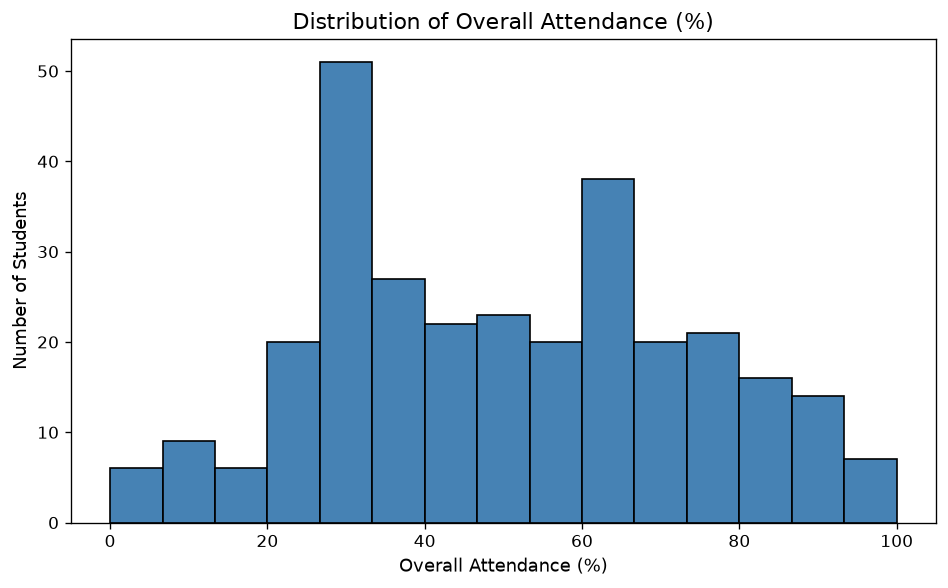

  Saved: hist_overall_attendance.png


In [10]:
# Cell 10 — Graph 1: Histogram of overall attendance
plt.figure(figsize=(8, 5))
plt.hist(df['overall_attendance_pct'], bins=15, color='steelblue', edgecolor='black')
plt.title('Distribution of Overall Attendance (%)')
plt.xlabel('Overall Attendance (%)')
plt.ylabel('Number of Students')
plt.tight_layout()
save_fig('hist_overall_attendance.png')

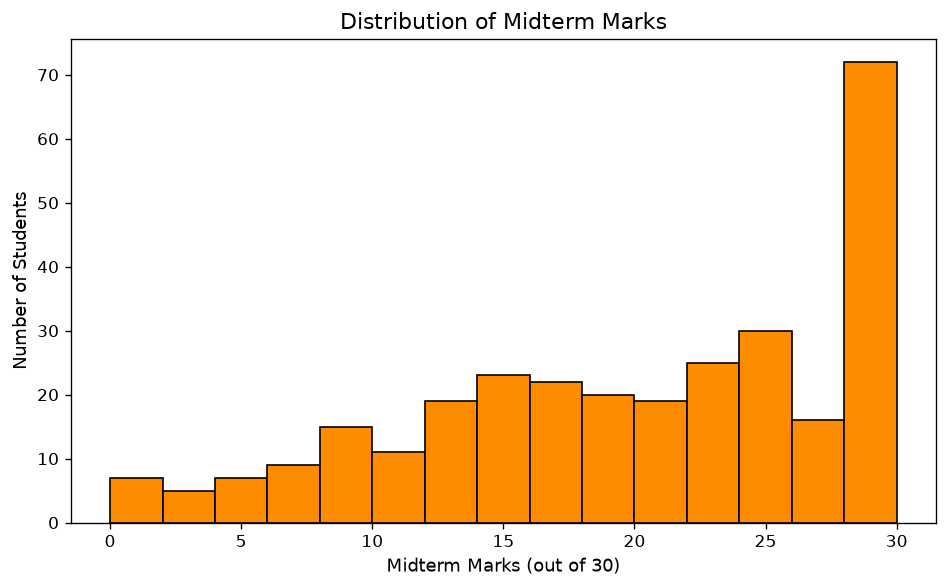

  Saved: hist_midterm_marks.png


In [11]:
# Cell 11 — Graph 2: Histogram of midterm marks
plt.figure(figsize=(8, 5))
plt.hist(df['midterm_marks'], bins=15, color='darkorange', edgecolor='black')
plt.title('Distribution of Midterm Marks')
plt.xlabel('Midterm Marks (out of 30)')
plt.ylabel('Number of Students')
plt.tight_layout()
save_fig('hist_midterm_marks.png')

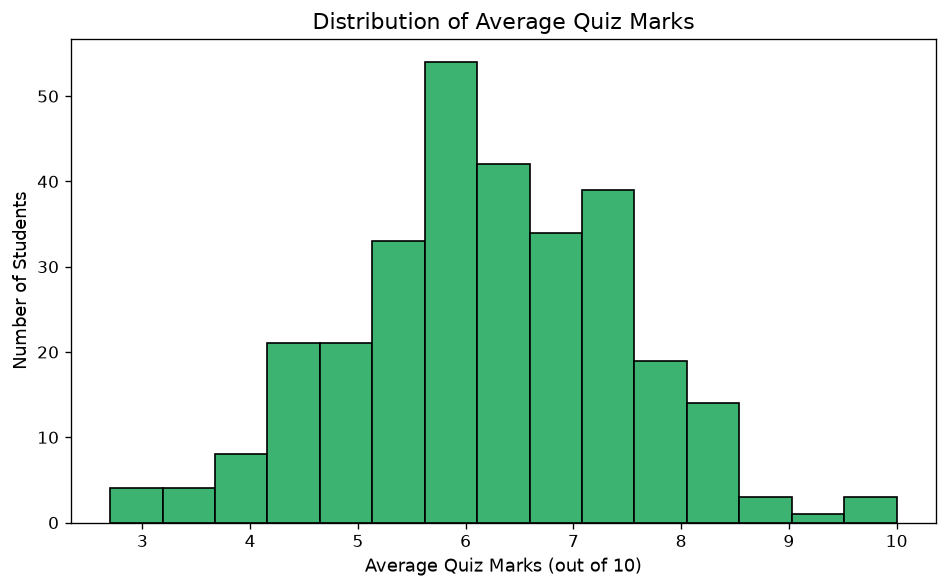

  Saved: hist_avg_quiz_marks.png


In [12]:
# Cell 12 — Graph 3: Histogram of average quiz marks
plt.figure(figsize=(8, 5))
plt.hist(df['avg_quiz_marks'], bins=15, color='mediumseagreen', edgecolor='black')
plt.title('Distribution of Average Quiz Marks')
plt.xlabel('Average Quiz Marks (out of 10)')
plt.ylabel('Number of Students')
plt.tight_layout()
save_fig('hist_avg_quiz_marks.png')

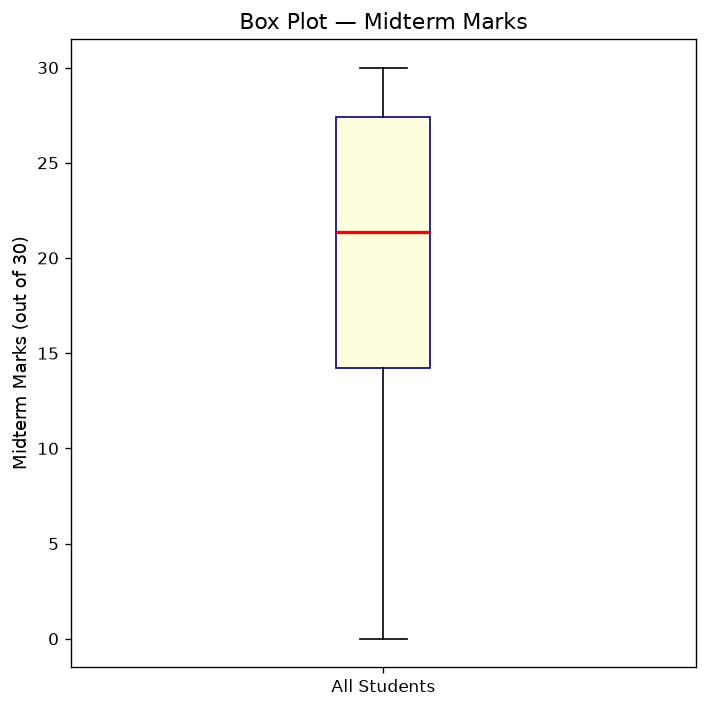

  Saved: boxplot_midterm.png


In [13]:
# Cell 13 — Graph 4: Box plot of midterm marks
plt.figure(figsize=(6, 6))
plt.boxplot(df['midterm_marks'].dropna(),
            patch_artist=True,
            boxprops=dict(facecolor='lightyellow', color='navy'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Box Plot — Midterm Marks')
plt.ylabel('Midterm Marks (out of 30)')
plt.xticks([1], ['All Students'])
plt.tight_layout()
save_fig('boxplot_midterm.png')

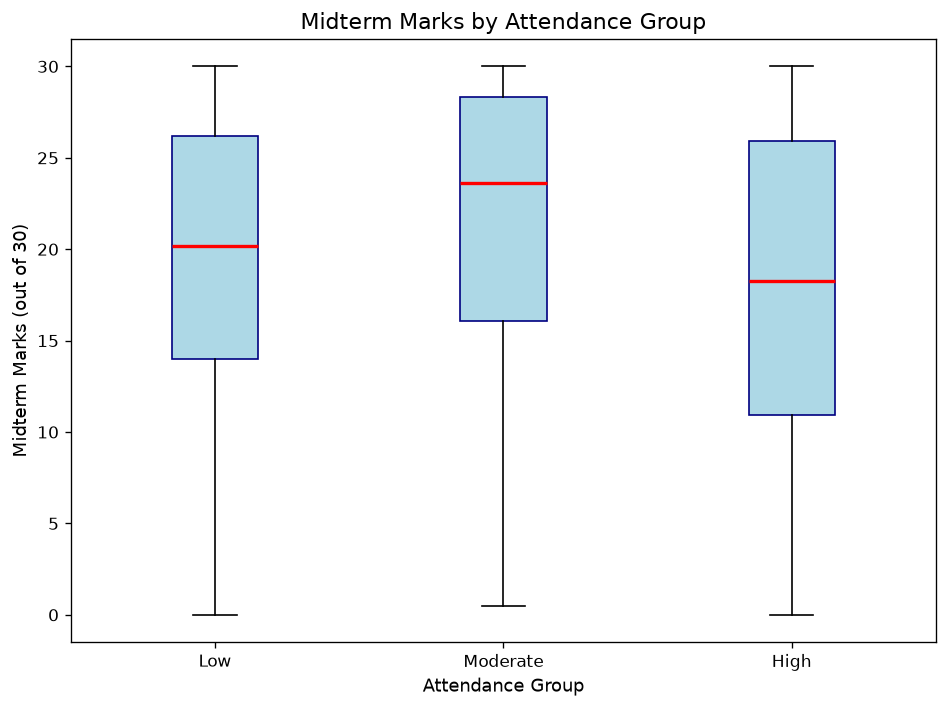

  Saved: boxplot_midterm_by_group.png


In [14]:
# Cell 14 — Graph 5: Box plot of midterm marks by attendance group
order = ['Low', 'Moderate', 'High']
groups_data = [df[df['attendance_group'] == g]['midterm_marks'].values for g in order]

plt.figure(figsize=(8, 6))
plt.boxplot(groups_data,
            tick_labels=order,
            patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Midterm Marks by Attendance Group')
plt.xlabel('Attendance Group')
plt.ylabel('Midterm Marks (out of 30)')
plt.tight_layout()
save_fig('boxplot_midterm_by_group.png')

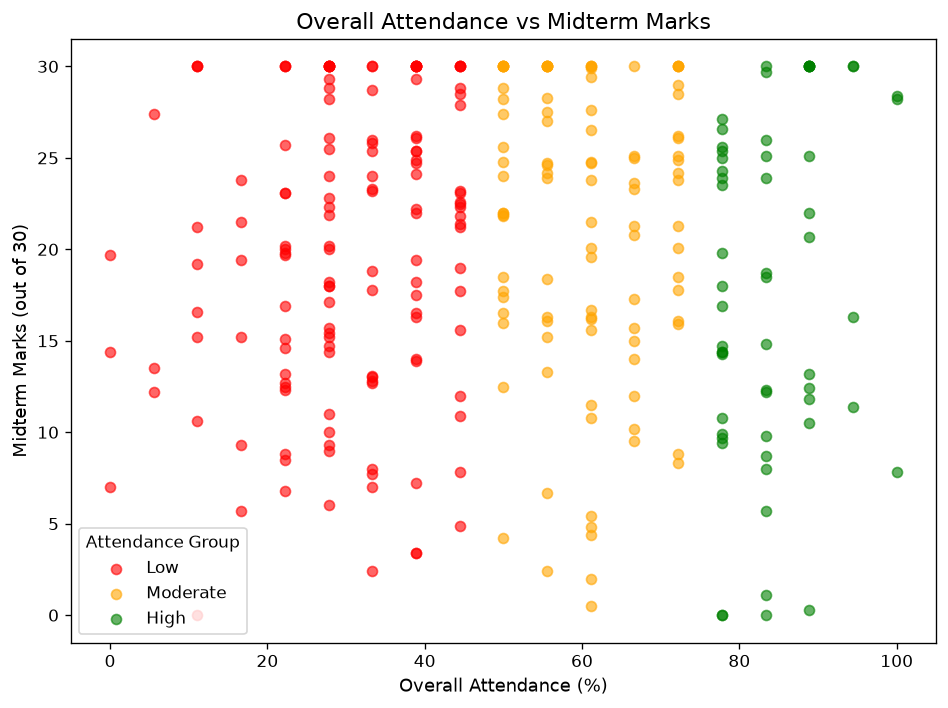

  Saved: scatter_attendance_vs_midterm.png


In [15]:
# Cell 15 — Graph 6: Scatter — attendance vs midterm marks
color_map = {'Low': 'red', 'Moderate': 'orange', 'High': 'green'}

plt.figure(figsize=(8, 6))
for grp, color in color_map.items():
    subset = df[df['attendance_group'] == grp]
    plt.scatter(subset['overall_attendance_pct'], subset['midterm_marks'],
                color=color, label=grp, alpha=0.6)
plt.title('Overall Attendance vs Midterm Marks')
plt.xlabel('Overall Attendance (%)')
plt.ylabel('Midterm Marks (out of 30)')
plt.legend(title='Attendance Group')
plt.tight_layout()
save_fig('scatter_attendance_vs_midterm.png')

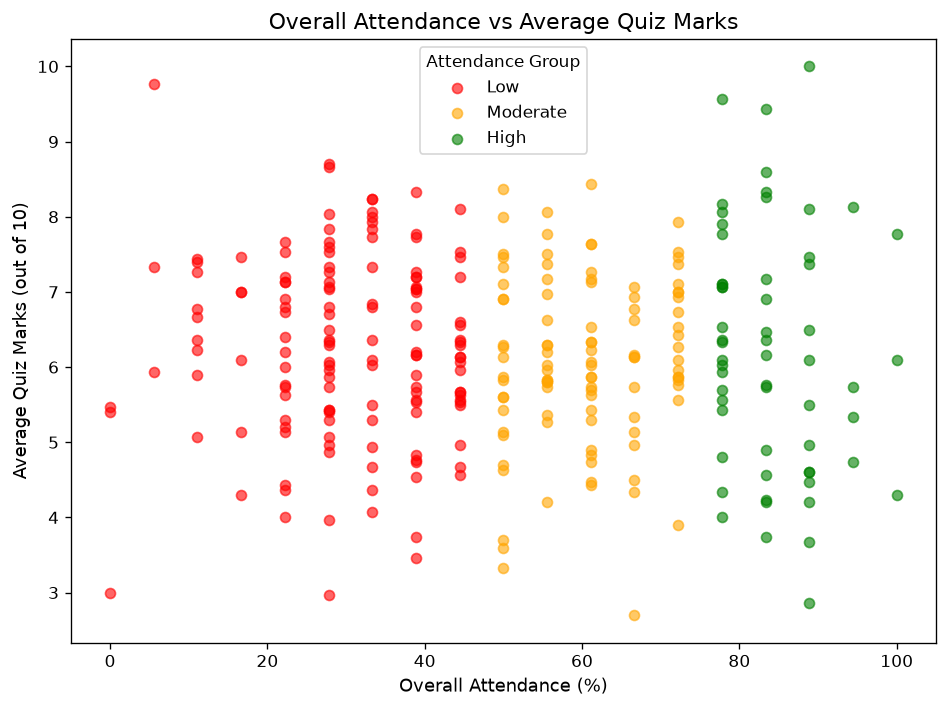

  Saved: scatter_attendance_vs_avg_quiz.png


In [16]:
# Cell 16 — Graph 7: Scatter — attendance vs average quiz marks
plt.figure(figsize=(8, 6))
for grp, color in color_map.items():
    subset = df[df['attendance_group'] == grp]
    plt.scatter(subset['overall_attendance_pct'], subset['avg_quiz_marks'],
                color=color, label=grp, alpha=0.6)
plt.title('Overall Attendance vs Average Quiz Marks')
plt.xlabel('Overall Attendance (%)')
plt.ylabel('Average Quiz Marks (out of 10)')
plt.legend(title='Attendance Group')
plt.tight_layout()
save_fig('scatter_attendance_vs_avg_quiz.png')

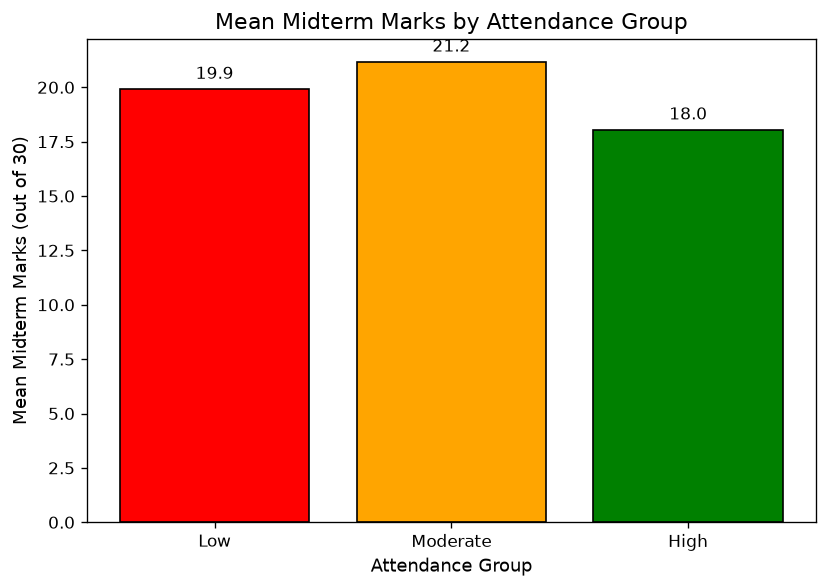

  Saved: bar_mean_midterm_by_group.png


In [17]:
# Cell 17 — Graph 8: Bar chart — mean midterm marks by attendance group
group_means = df.groupby('attendance_group')['midterm_marks'].mean().reindex(order)

plt.figure(figsize=(7, 5))
bars = plt.bar(order, group_means.values, color=['red', 'orange', 'green'], edgecolor='black')
for bar, val in zip(bars, group_means.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             f'{val:.1f}', ha='center', va='bottom', fontsize=10)
plt.title('Mean Midterm Marks by Attendance Group')
plt.xlabel('Attendance Group')
plt.ylabel('Mean Midterm Marks (out of 30)')
plt.tight_layout()
save_fig('bar_mean_midterm_by_group.png')

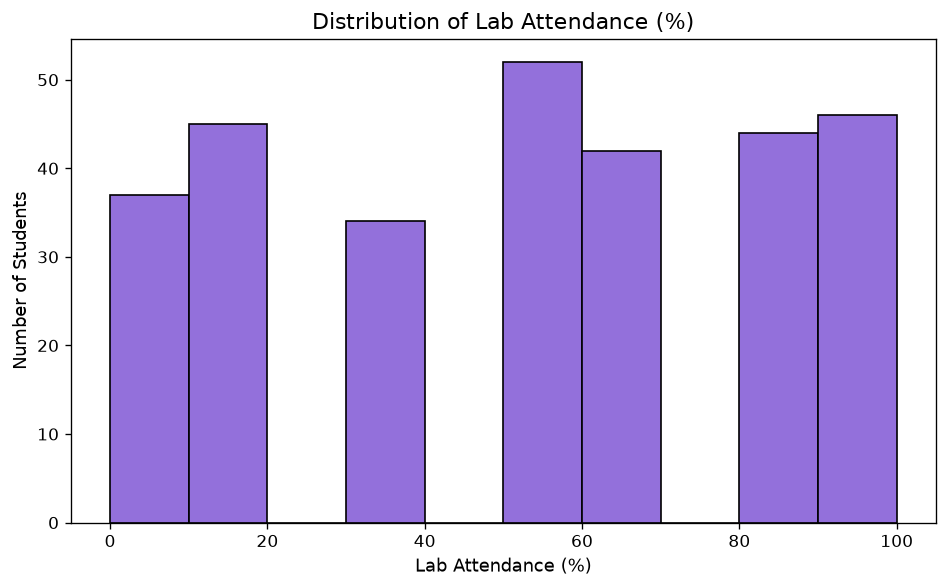

  Saved: hist_lab_attendance.png


In [18]:
# Cell 18 — Graph 9: Histogram of lab attendance
plt.figure(figsize=(8, 5))
plt.hist(df['lab_attendance_pct'], bins=10, color='mediumpurple', edgecolor='black')
plt.title('Distribution of Lab Attendance (%)')
plt.xlabel('Lab Attendance (%)')
plt.ylabel('Number of Students')
plt.tight_layout()
save_fig('hist_lab_attendance.png')

---
## Part C — 95% Confidence Interval for Mean Midterm Marks

In [19]:
# Cell 19 — Compute CI step by step
# Formula: CI = x_bar +/- t_critical * (s / sqrt(n))

midterm_vals = df['midterm_marks'].values

n       = len(midterm_vals)                      # Sample size
x_bar   = np.mean(midterm_vals)                  # Sample mean
s       = np.std(midterm_vals, ddof=1)           # Sample standard deviation
df_t    = n - 1                                  # Degrees of freedom
alpha   = 0.05
t_crit  = stats.t.ppf(1 - alpha / 2, df=df_t)   # Two-tailed critical t-value
se      = s / np.sqrt(n)                         # Standard error of the mean
moe     = t_crit * se                            # Margin of error
ci_lo   = x_bar - moe                            # Lower confidence limit
ci_hi   = x_bar + moe                            # Upper confidence limit

print(f'n                      = {n}')
print(f'Sample Mean (x̄)        = {x_bar:.4f}')
print(f'Sample Std Dev (s)      = {s:.4f}')
print(f'Degrees of Freedom      = {df_t}')
print(f'Critical t (95%, 2-tail)= {t_crit:.4f}')
print(f'Standard Error (SE)     = {se:.4f}')
print(f'Margin of Error         = {moe:.4f}')
print(f'95% Confidence Interval = ({ci_lo:.4f}, {ci_hi:.4f})')

n                      = 300
Sample Mean (x̄)        = 19.9690
Sample Std Dev (s)      = 8.2722
Degrees of Freedom      = 299
Critical t (95%, 2-tail)= 1.9679
Standard Error (SE)     = 0.4776
Margin of Error         = 0.9399
95% Confidence Interval = (19.0291, 20.9089)


In [20]:
# Cell 20 — Interpretation
print('Interpretation:')
print(f'  We are 95% confident that the true mean midterm marks lies between')
print(f'  {ci_lo:.2f} and {ci_hi:.2f} (out of 30).')
print()
print('Limitation:')
print('  This dataset is synthetic and its sampling process is undocumented.')
print('  This confidence interval applies to this dataset only and cannot be')
print('  generalised to any real student population.')

# Save
ci_results = {
    'n': n, 'mean': round(x_bar,4), 'std_dev': round(s,4), 'df': df_t,
    't_critical': round(t_crit,4), 'std_error': round(se,4),
    'margin_of_error': round(moe,4),
    'ci_lower_95': round(ci_lo,4), 'ci_upper_95': round(ci_hi,4)
}
pd.Series(ci_results).to_csv(os.path.join(RESULTS, 'confidence_interval_midterm.csv'), header=['Value'])
print('\nSaved: confidence_interval_midterm.csv')

Interpretation:
  We are 95% confident that the true mean midterm marks lies between
  19.03 and 20.91 (out of 30).

Limitation:
  This dataset is synthetic and its sampling process is undocumented.
  This confidence interval applies to this dataset only and cannot be
  generalised to any real student population.

Saved: confidence_interval_midterm.csv


---
## Part D — Hypothesis Testing

In [21]:
# Cell 21 — Prepare attendance groups
low_grp  = df[df['attendance_group'] == 'Low']['midterm_marks'].values
mod_grp  = df[df['attendance_group'] == 'Moderate']['midterm_marks'].values
high_grp = df[df['attendance_group'] == 'High']['midterm_marks'].values

print('Low attendance    — n=%d, mean=%.4f' % (len(low_grp),  np.mean(low_grp)))
print('Moderate attend.  — n=%d, mean=%.4f' % (len(mod_grp),  np.mean(mod_grp)))
print('High attendance   — n=%d, mean=%.4f' % (len(high_grp), np.mean(high_grp)))

Low attendance    — n=141, mean=19.9078
Moderate attend.  — n=101, mean=21.1624
High attendance   — n=58, mean=18.0397


In [22]:
# Cell 22 — Assumption check: Levene's test for equal variances
# H0: All groups have equal variance.
# If p < 0.05, equal variance cannot be assumed. Use Welch's t-test.

lev_stat, lev_p = stats.levene(low_grp, mod_grp, high_grp)
print(f"Levene's test: stat={lev_stat:.4f}, p={lev_p:.4f}")
if lev_p < 0.05:
    print('  Conclusion: Unequal variances. Use Welch\'s t-test (equal_var=False).')
else:
    print('  Conclusion: No significant difference in variances (but we still use Welch\'s to be safe).')

Levene's test: stat=2.4612, p=0.0871
  Conclusion: No significant difference in variances (but we still use Welch's to be safe).


In [23]:
# Cell 23 — Test 1: Welch's independent-samples t-test (Low vs High)
# H0: Mean midterm marks are equal for Low and High attendance groups.
# H1: They are not equal.
# alpha = 0.05

t_stat, p_val = stats.ttest_ind(low_grp, high_grp, equal_var=False)  # Welch's t-test
alpha_t = 0.05

print('=== Welch\'s Independent Samples t-test ===')
print(f'Group means — Low: {np.mean(low_grp):.4f}, High: {np.mean(high_grp):.4f}')
print(f't-statistic = {t_stat:.4f}')
print(f'p-value     = {p_val:.6f}')
print(f'alpha       = {alpha_t}')

if p_val < alpha_t:
    decision_t = 'Reject H0'
    interp_t   = 'There is a statistically significant difference in midterm marks between groups.'
else:
    decision_t = 'Fail to Reject H0'
    interp_t   = 'No statistically significant difference found between Low and High attendance groups.'

print(f'Decision    = {decision_t}')
print(f'Interpretation: {interp_t}')

=== Welch's Independent Samples t-test ===
Group means — Low: 19.9078, High: 18.0397
t-statistic = 1.3392
p-value     = 0.183787
alpha       = 0.05
Decision    = Fail to Reject H0
Interpretation: No statistically significant difference found between Low and High attendance groups.


In [24]:
# Cell 24 — Save t-test results
t_results = {
    'low_n': len(low_grp), 'low_mean': round(np.mean(low_grp),4),
    'high_n': len(high_grp), 'high_mean': round(np.mean(high_grp),4),
    't_statistic': round(t_stat,4), 'p_value': round(p_val,6),
    'alpha': alpha_t, 'decision': decision_t
}
pd.Series(t_results).to_csv(os.path.join(RESULTS, 'ttest_low_vs_high.csv'), header=['Value'])
print('Saved: ttest_low_vs_high.csv')

Saved: ttest_low_vs_high.csv


In [25]:
# Cell 25 — Test 2: One-way ANOVA (all three groups)
# H0: Mean midterm marks are equal across all three attendance groups.
# H1: At least one group has a different mean.
# alpha = 0.05

f_stat, p_anova = stats.f_oneway(low_grp, mod_grp, high_grp)

print('=== One-Way ANOVA ===')
print(f'Group means — Low: {np.mean(low_grp):.4f}, Moderate: {np.mean(mod_grp):.4f}, High: {np.mean(high_grp):.4f}')
print(f'F-statistic = {f_stat:.4f}')
print(f'p-value     = {p_anova:.6f}')

if p_anova < 0.05:
    decision_anova = 'Reject H0'
    interp_anova   = 'At least one group has a significantly different mean midterm mark.'
else:
    decision_anova = 'Fail to Reject H0'
    interp_anova   = 'No significant difference in mean midterm marks across the three groups at alpha=0.05.'

print(f'Decision    = {decision_anova}')
print(f'Interpretation: {interp_anova}')
print()
print('Note: p =', round(p_anova,4), '— marginal. This dataset is synthetic; results cannot generalise.')

=== One-Way ANOVA ===
Group means — Low: 19.9078, Moderate: 21.1624, High: 18.0397
F-statistic = 2.6616
p-value     = 0.071500
Decision    = Fail to Reject H0
Interpretation: No significant difference in mean midterm marks across the three groups at alpha=0.05.

Note: p = 0.0715 — marginal. This dataset is synthetic; results cannot generalise.


In [26]:
# Cell 26 — Save ANOVA results
anova_results = {
    'low_n': len(low_grp), 'low_mean': round(np.mean(low_grp),4),
    'mod_n': len(mod_grp), 'mod_mean': round(np.mean(mod_grp),4),
    'high_n': len(high_grp), 'high_mean': round(np.mean(high_grp),4),
    'F_statistic': round(f_stat,4), 'p_value': round(p_anova,6),
    'levene_stat': round(lev_stat,4), 'levene_p': round(lev_p,6),
    'alpha': 0.05, 'decision': decision_anova
}
pd.Series(anova_results).to_csv(os.path.join(RESULTS, 'anova_attendance_groups.csv'), header=['Value'])
print('Saved: anova_attendance_groups.csv')

Saved: anova_attendance_groups.csv


---
## Part E — Correlation Analysis

In [27]:
# Cell 27 — Pearson correlation: overall attendance vs academic outcomes
targets = [
    ('midterm_marks',  'Midterm Marks'),
    ('avg_quiz_marks', 'Avg Quiz Marks'),
    ('final_marks',    'Final Marks'),
    ('previous_gpa',   'Previous GPA'),
]

print('Pearson Correlation: Overall Attendance % vs Academic Variables')
print(f'{"Variable":<20}  {"r":>8}  {"p-value":>12}  Strength')
print('-' * 55)

corr_rows = []
for col, label in targets:
    r, p = stats.pearsonr(df['overall_attendance_pct'], df[col])
    abs_r = abs(r)
    if abs_r >= 0.7:
        strength = 'Strong'
    elif abs_r >= 0.4:
        strength = 'Moderate'
    elif abs_r >= 0.2:
        strength = 'Weak'
    else:
        strength = 'Negligible'
    direction = 'positive' if r >= 0 else 'negative'
    print(f'{label:<20}  {r:>8.4f}  {p:>12.6f}  {strength} {direction}')
    corr_rows.append({'Variable': label, 'r': round(r,4), 'p_value': round(p,6), 'strength': strength})

pd.DataFrame(corr_rows).to_csv(os.path.join(RESULTS, 'pearson_correlation_attendance.csv'), index=False)

Pearson Correlation: Overall Attendance % vs Academic Variables
Variable                     r       p-value  Strength
-------------------------------------------------------
Midterm Marks           0.0015      0.978957  Negligible positive
Avg Quiz Marks         -0.0357      0.537760  Negligible negative
Final Marks             0.0343      0.553569  Negligible positive
Previous GPA           -0.0380      0.512463  Negligible negative


In [28]:
# Cell 28 — Correlation matrix for all key numeric variables
corr_cols = [
    'overall_attendance_pct', 'lecture_attendance_pct', 'lab_attendance_pct',
    'avg_quiz_marks', 'midterm_marks', 'final_marks', 'previous_gpa', 'age'
]
corr_matrix = df[corr_cols].corr(method='pearson').round(4)
corr_matrix.to_csv(os.path.join(RESULTS, 'correlation_matrix.csv'))
print('Correlation matrix saved.')
corr_matrix

Correlation matrix saved.


,overall_attendance_pct,lecture_attendance_pct,lab_attendance_pct,avg_quiz_marks,midterm_marks,final_marks,previous_gpa,age
overall_attendance_pct,1.0000,0.8810,0.4574,-0.0357,0.0015,0.0343,-0.0380,-0.0311
lecture_attendance_pct,0.8810,1.0000,-0.0179,-0.0572,0.0120,-0.0189,-0.0220,-0.0249
lab_attendance_pct,0.4574,-0.0179,1.0000,0.0321,-0.0194,0.1081,-0.0389,-0.0189
avg_quiz_marks,-0.0357,-0.0572,0.0321,1.0000,-0.0505,0.1841,-0.0336,0.1057
midterm_marks,0.0015,0.0120,-0.0194,-0.0505,1.0000,-0.0630,0.0136,0.0213
final_marks,0.0343,-0.0189,0.1081,0.1841,-0.0630,1.0000,0.1011,-0.0319
previous_gpa,-0.0380,-0.0220,-0.0389,-0.0336,0.0136,0.1011,1.0000,0.0180
age,-0.0311,-0.0249,-0.0189,0.1057,0.0213,-0.0319,0.0180,1.0000


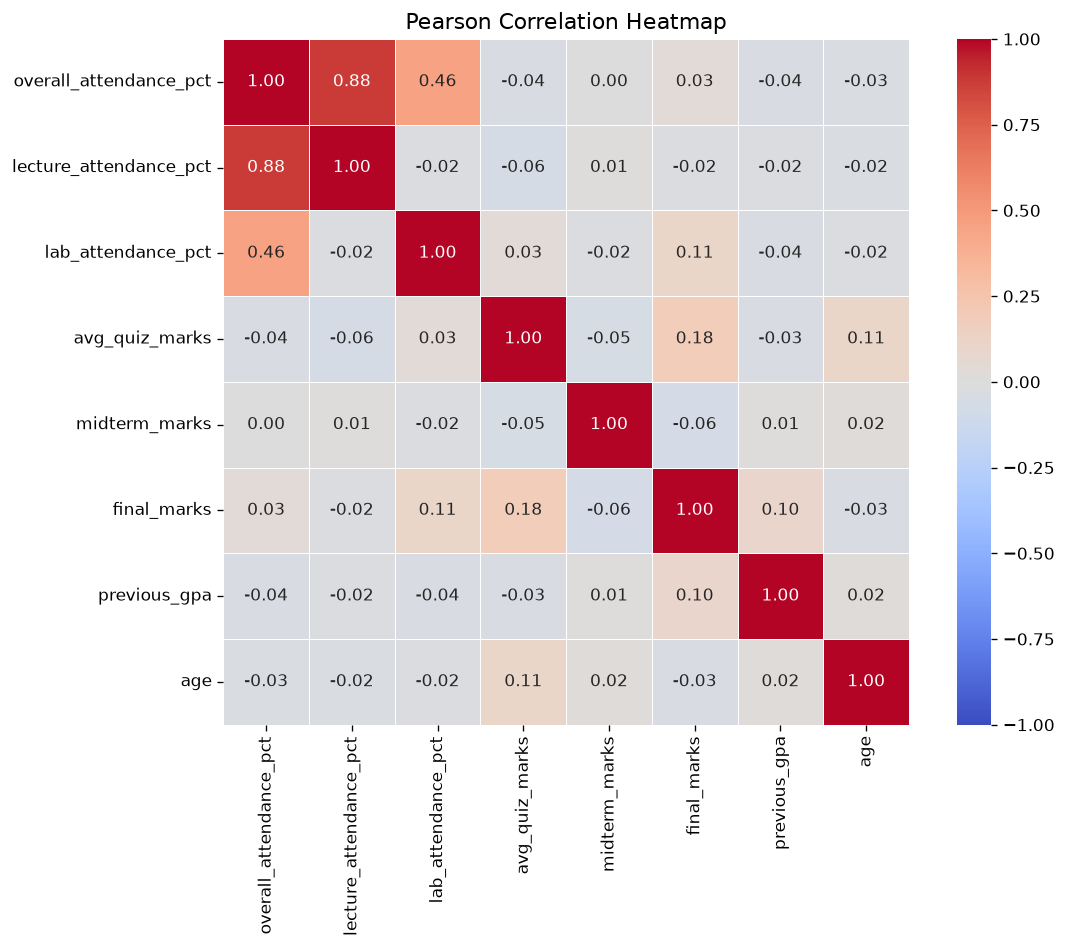

  Saved: heatmap_correlation.png

Note: Correlation does not establish causation.
Even if attendance correlates with marks, it does not prove that
attending class causes higher marks — other variables may explain both.


In [29]:
# Cell 29 — Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1, square=True)
plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
save_fig('heatmap_correlation.png')

print('\nNote: Correlation does not establish causation.')
print('Even if attendance correlates with marks, it does not prove that')
print('attending class causes higher marks — other variables may explain both.')

---
## Part F — Simple Linear Regression

In [30]:
# Cell 30 — Prepare data for SLR
# X: overall_attendance_pct (independent variable)
# y: midterm_marks (dependent variable / target)

X_simple = df[['overall_attendance_pct']].values   # 2D array required by sklearn
y        = df['midterm_marks'].values

print('X shape:', X_simple.shape)
print('y shape:', y.shape)

X shape: (300, 1)
y shape: (300,)


In [31]:
# Cell 31 — Train/test split (80:20, random_state=42 for reproducibility)
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
print('Training samples:', len(X_tr_s))
print('Test samples    :', len(X_te_s))

Training samples: 240
Test samples    : 60


In [32]:
# Cell 32 — Train simple linear regression model
slr = LinearRegression()
slr.fit(X_tr_s, y_tr_s)   # Learns intercept and slope from training data only

b0 = slr.intercept_       # y-intercept: predicted midterm when attendance = 0
b1 = slr.coef_[0]         # Slope: change in midterm marks per 1% attendance increase

print(f'Intercept (b0) = {b0:.4f}')
print(f'Coefficient (b1) = {b1:.4f}')
print()
print(f'Regression equation:')
print(f'  Midterm = {b0:.4f} + ({b1:.4f}) x Overall_Attendance_%')
print()
print(f'Interpretation:')
print(f'  For every 1% increase in attendance, midterm marks change by {b1:.4f} marks.')
print(f'  The intercept {b0:.4f} is the predicted midterm if attendance were 0% (theoretical).')

Intercept (b0) = 20.7955
Coefficient (b1) = -0.0157

Regression equation:
  Midterm = 20.7955 + (-0.0157) x Overall_Attendance_%

Interpretation:
  For every 1% increase in attendance, midterm marks change by -0.0157 marks.
  The intercept 20.7955 is the predicted midterm if attendance were 0% (theoretical).


In [33]:
# Cell 33 — Predict on test set (never seen during training)
y_pred_s = slr.predict(X_te_s)
print('First 5 actual vs predicted:')
for actual, pred in zip(y_te_s[:5], y_pred_s[:5]):
    print(f'  Actual: {actual:.1f}  Predicted: {pred:.4f}')

First 5 actual vs predicted:
  Actual: 23.1  Predicted: 20.4461
  Actual: 12.7  Predicted: 20.2714
  Actual: 22.8  Predicted: 20.3588
  Actual: 16.9  Predicted: 20.4461
  Actual: 25.4  Predicted: 20.1841


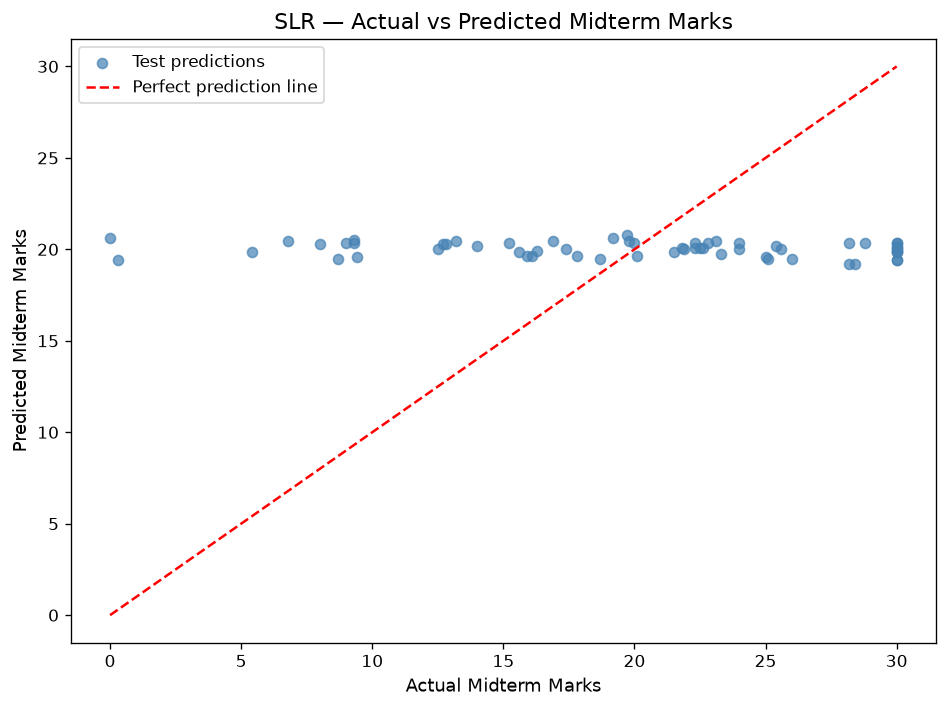

  Saved: slr_actual_vs_predicted.png


In [34]:
# Cell 34 — Plot: Actual vs Predicted (SLR)
plt.figure(figsize=(8, 6))
plt.scatter(y_te_s, y_pred_s, color='steelblue', alpha=0.7, label='Test predictions')
lo = min(y_te_s.min(), y_pred_s.min())
hi = max(y_te_s.max(), y_pred_s.max())
plt.plot([lo, hi], [lo, hi], 'r--', label='Perfect prediction line')
plt.title('SLR — Actual vs Predicted Midterm Marks')
plt.xlabel('Actual Midterm Marks')
plt.ylabel('Predicted Midterm Marks')
plt.legend()
plt.tight_layout()
save_fig('slr_actual_vs_predicted.png')

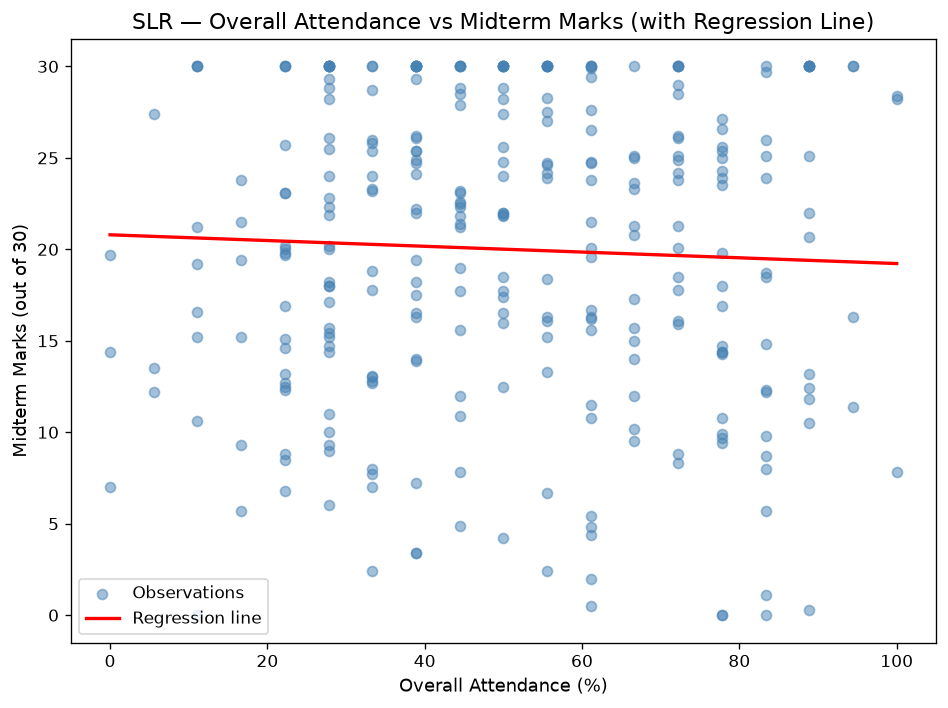

  Saved: slr_regression_line.png


In [35]:
# Cell 35 — Plot: Regression line across all observations
x_line = np.linspace(0, 100, 200).reshape(-1, 1)
y_line = slr.predict(x_line)

plt.figure(figsize=(8, 6))
plt.scatter(df['overall_attendance_pct'], df['midterm_marks'],
            color='steelblue', alpha=0.5, label='Observations')
plt.plot(x_line, y_line, color='red', linewidth=2, label='Regression line')
plt.title('SLR — Overall Attendance vs Midterm Marks (with Regression Line)')
plt.xlabel('Overall Attendance (%)')
plt.ylabel('Midterm Marks (out of 30)')
plt.legend()
plt.tight_layout()
save_fig('slr_regression_line.png')

---
## Part G — Multiple Linear Regression

In [36]:
# Cell 36 — Feature selection justification
# Features chosen:
#   overall_attendance_pct — primary variable of interest
#   avg_quiz_marks         — reflects ongoing academic engagement
#   previous_gpa           — historical academic ability
#   age                    — demographic variable (included for completeness)
#
# Excluded:
#   student_id, name       — identifiers only
#   gender                 — no clear statistical justification added
#   final_marks            — cannot be used to predict midterm (data leakage if exam scores are related)
#   midterm_marks          — this is the target variable itself

feature_cols = ['overall_attendance_pct', 'avg_quiz_marks', 'previous_gpa', 'age']

X_multi = df[feature_cols].values
y_multi = df['midterm_marks'].values

print('Features:', feature_cols)
print('X shape:', X_multi.shape)

Features: ['overall_attendance_pct', 'avg_quiz_marks', 'previous_gpa', 'age']
X shape: (300, 4)


In [37]:
# Cell 37 — Same 80:20 split with same random_state=42
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)
print('Training samples:', len(X_tr_m))
print('Test samples    :', len(X_te_m))

Training samples: 240
Test samples    : 60


In [38]:
# Cell 38 — Train multiple linear regression
mlr = LinearRegression()
mlr.fit(X_tr_m, y_tr_m)   # Fitted on training data only

b0_m = mlr.intercept_
coefs = mlr.coef_

print('Intercept:', round(b0_m, 4))
print('\nCoefficients:')
for fname, coef in zip(feature_cols, coefs):
    print(f'  {fname:<28}: {coef:.4f}')

eq = ' + '.join([f'({c:.4f})*{f}' for f, c in zip(feature_cols, coefs)])
print(f'\nEquation:')
print(f'  Midterm = {b0_m:.4f} + {eq}')

Intercept: 24.8117

Coefficients:
  overall_attendance_pct      : -0.0189
  avg_quiz_marks              : -0.6408
  previous_gpa                : 0.0595
  age                         : -0.0028

Equation:
  Midterm = 24.8117 + (-0.0189)*overall_attendance_pct + (-0.6408)*avg_quiz_marks + (0.0595)*previous_gpa + (-0.0028)*age


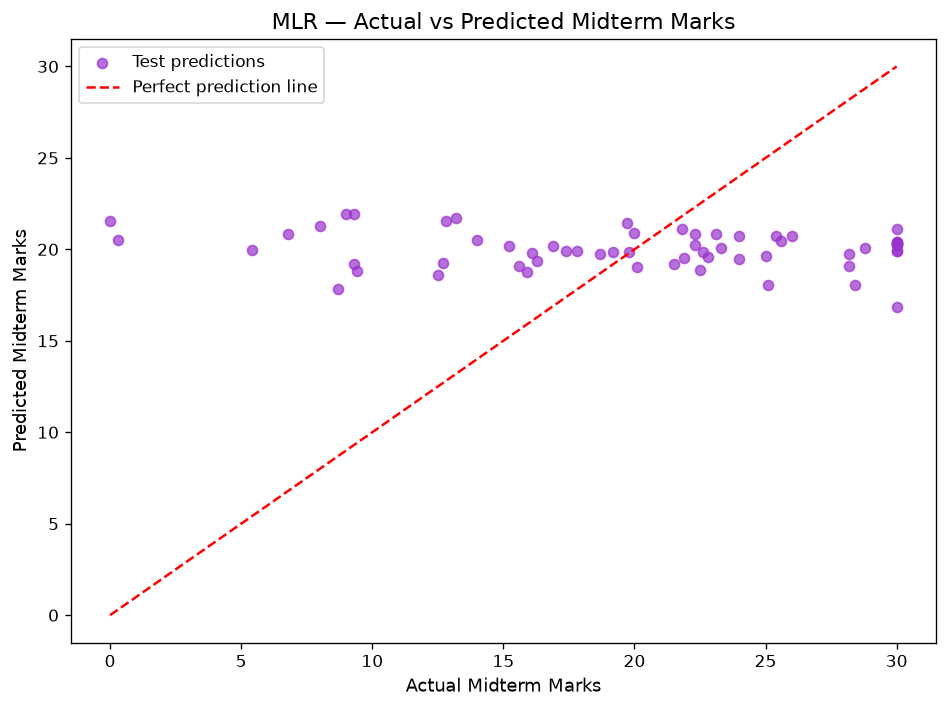

  Saved: mlr_actual_vs_predicted.png


In [39]:
# Cell 39 — Predict on test set (MLR)
y_pred_m = mlr.predict(X_te_m)

plt.figure(figsize=(8, 6))
plt.scatter(y_te_m, y_pred_m, color='darkorchid', alpha=0.7, label='Test predictions')
lo = min(y_te_m.min(), y_pred_m.min())
hi = max(y_te_m.max(), y_pred_m.max())
plt.plot([lo, hi], [lo, hi], 'r--', label='Perfect prediction line')
plt.title('MLR — Actual vs Predicted Midterm Marks')
plt.xlabel('Actual Midterm Marks')
plt.ylabel('Predicted Midterm Marks')
plt.legend()
plt.tight_layout()
save_fig('mlr_actual_vs_predicted.png')

---
## Part H — Model Evaluation

In [40]:
# Cell 40 — Compute evaluation metrics for both models
# MAE  = Mean Absolute Error       — average absolute difference between actual and predicted
# MSE  = Mean Squared Error        — penalises large errors more than small ones
# RMSE = sqrt(MSE)                 — in the same units as the target variable
# R²   = Coefficient of determination — proportion of variance explained by the model

mae_s  = mean_absolute_error(y_te_s, y_pred_s)
mse_s  = mean_squared_error(y_te_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s   = r2_score(y_te_s, y_pred_s)

mae_m  = mean_absolute_error(y_te_m, y_pred_m)
mse_m  = mean_squared_error(y_te_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m   = r2_score(y_te_m, y_pred_m)

eval_df = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Simple LR': [round(mae_s,4), round(mse_s,4), round(rmse_s,4), round(r2_s,4)],
    'Multiple LR': [round(mae_m,4), round(mse_m,4), round(rmse_m,4), round(r2_m,4)]
})
eval_df

,Metric,Simple LR,Multiple LR
0,MAE,6.6292,6.6987
1,MSE,64.3656,67.1423
2,RMSE,8.0228,8.1940
3,R²,-0.0198,-0.0637


In [41]:
# Cell 41 — Interpretation of model evaluation
print('Model Evaluation Interpretation')
print('=' * 50)
print(f'Simple LR  — RMSE: {rmse_s:.4f}, R²: {r2_s:.4f}')
print(f'Multiple LR — RMSE: {rmse_m:.4f}, R²: {r2_m:.4f}')
print()
print('- Both models have negative R², meaning they perform worse than')
print('  a simple horizontal line at the mean (a baseline model).')
print('- This confirms that overall attendance, quiz marks, GPA, and age')
print('  do not reliably predict midterm marks in this dataset.')
print('- The RMSE (~8 marks out of 30) is large relative to the scale.')
print('- This is an important and honest finding: in this synthetic dataset,')
print('  attendance does not drive academic performance as strongly as expected.')
print()
print('Limitation: This dataset is synthetic. These findings do not reflect')
print('real-world student populations.')

# Save
eval_df.to_csv(os.path.join(RESULTS, 'model_evaluation_comparison.csv'), index=False)
print('\nSaved: model_evaluation_comparison.csv')

Model Evaluation Interpretation
Simple LR  — RMSE: 8.0228, R²: -0.0198
Multiple LR — RMSE: 8.1940, R²: -0.0637

- Both models have negative R², meaning they perform worse than
  a simple horizontal line at the mean (a baseline model).
- This confirms that overall attendance, quiz marks, GPA, and age
  do not reliably predict midterm marks in this dataset.
- The RMSE (~8 marks out of 30) is large relative to the scale.
- This is an important and honest finding: in this synthetic dataset,
  attendance does not drive academic performance as strongly as expected.

Limitation: This dataset is synthetic. These findings do not reflect
real-world student populations.

Saved: model_evaluation_comparison.csv


---
## Part I — Predictions on Unseen Test Data

In [42]:
# Cell 42 — Build prediction table from held-out test set
# These 60 observations were never used during model training.

predictions_df = pd.DataFrame({
    'Actual_Midterm' : y_te_m,
    'SLR_Predicted'  : y_pred_s.round(4),
    'SLR_Error'      : (y_te_m - y_pred_s).round(4),
    'MLR_Predicted'  : y_pred_m.round(4),
    'MLR_Error'      : (y_te_m - y_pred_m).round(4),
}).reset_index(drop=True)
predictions_df.index.name = 'Test_Index'

print('First 10 test predictions:')
predictions_df.head(10)

First 10 test predictions:


,Actual_Midterm,SLR_Predicted,SLR_Error,MLR_Predicted,MLR_Error
Test_Index,,,,,
0,23.1,20.4461,2.6539,20.8345,2.2655
1,12.7,20.2714,-7.5714,19.2746,-6.5746
2,22.8,20.3588,2.4412,19.5689,3.2311
3,16.9,20.4461,-3.5461,20.1926,-3.2926
4,25.4,20.1841,5.2159,20.7530,4.6470
5,21.8,20.0967,1.7033,21.1226,0.6774
6,9.0,20.3588,-11.3588,21.9191,-12.9191
7,19.8,20.4461,-0.6461,19.8697,-0.0697
8,9.4,19.5727,-10.1727,18.8431,-9.4431


In [43]:
# Cell 43 — Save all predictions
predictions_df.to_csv(os.path.join(RESULTS, 'predictions_test_set.csv'))
print(f'Saved {len(predictions_df)} predictions to: predictions_test_set.csv')
print('\nAll outputs complete.')

Saved 60 predictions to: predictions_test_set.csv

All outputs complete.


In [44]:
# Cell 44 — Final file summary
import glob

print('=== Graphs saved ===')
for f in sorted(glob.glob(os.path.join(GRAPHS, '*.png'))):
    print(' ', os.path.basename(f))

print('\n=== Results saved ===')
for f in sorted(glob.glob(os.path.join(RESULTS, '*.csv'))):
    print(' ', os.path.basename(f))

=== Graphs saved ===
  bar_mean_midterm_by_group.png
  boxplot_midterm.png
  boxplot_midterm_by_group.png
  heatmap_correlation.png
  hist_avg_quiz_marks.png
  hist_lab_attendance.png
  hist_midterm_marks.png
  hist_overall_attendance.png
  mlr_actual_vs_predicted.png
  scatter_attendance_vs_avg_quiz.png
  scatter_attendance_vs_midterm.png
  slr_actual_vs_predicted.png
  slr_regression_line.png

=== Results saved ===
  anova_attendance_groups.csv
  attendance_group_summary.csv
  confidence_interval_midterm.csv
  correlation_matrix.csv
  descriptive_statistics.csv
  model_evaluation_comparison.csv
  pearson_correlation_attendance.csv
  predictions_test_set.csv
  ttest_low_vs_high.csv
